# 完整传播：连续 pp 冷却与分立 pp 碰撞比较

读取 `transport_loss.cpp` 和 `transport_loss_stochastic.cpp` 的新格式输出。两者包含扩散、线性风、绝热冷却和 pp 能损；连续版采用联合冷却 ODE 的 RK4 数值解，并非闭式解析解。分立版逐事件抽样 pp 碰撞。所有图使用相同的粒子初始条件与分箱。

默认运行：10,000 个质子从原点瞬时注入，总能量 $E_0=10$–$10^6$ GeV 对数等间隔，$dN/dE_0\propto E_0^{-1}$；$n_H=0.1$ cm$^{-3}$，$u_z=az$，$a=10^{-8}$ yr$^{-1}$，传播 $10^9$ yr，步长 1000 yr。实际参数从各自的参数文件读取并核对。初始质子等权重，没有逃逸边界。

可从项目根目录或 `output/` 运行。只读取输出，不重新执行模拟。旧的四列末态和两列观测环文件不适用。

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

continuous_prefix = 'transport_continuous_t1e9'
discrete_prefix = 'transport_discrete_t1e9'
data_dir = Path('.')
if not (data_dir / (continuous_prefix + '_final.bin')).exists():
    data_dir = Path('output')
m_p = 0.938272              # GeV
c_cm_s = 2.99792458e10
yr2s = 31557600.0


def read_parameters(prefix):
    parameters = {}
    with open(data_dir / (prefix + '_parameters.txt')) as file:
        for line in file:
            name, value = line.split()
            parameters[name] = float(value)
    return parameters


parameters_c = read_parameters(continuous_prefix)
parameters_d = read_parameters(discrete_prefix)
for name in parameters_c:
    if name != 'stochastic':
        assert parameters_c[name] == parameters_d[name], 'Mismatched parameter: ' + name
assert parameters_c['stochastic'] == 0 and parameters_d['stochastic'] == 1
N = int(parameters_c['N_particles'])
T_end = parameters_c['T_end_yr']
nH = parameters_c['nH_cm-3']
a = parameters_c['a_yr-1']
kappa = parameters_c['kappa']

# Native-endian float64, eight columns:
# id, time[yr], E_initial[GeV], x[pc], y[pc], z[pc], E_total[GeV], collision count.
final_c = np.fromfile(data_dir / (continuous_prefix + '_final.bin'), dtype='=f8').reshape(-1, 8)
final_d = np.fromfile(data_dir / (discrete_prefix + '_final.bin'), dtype='=f8').reshape(-1, 8)
assert final_c.shape == final_d.shape == (N, 8)
assert np.array_equal(final_c[:, :3], final_d[:, :3])
assert np.array_equal(final_c[:, 0], np.arange(N))
assert np.all(final_c[:, 7] == -1)  # continuous model has no collision count
T0 = final_c[:, 2] - m_p
T_c = final_c[:, 6] - m_p
T_d = final_d[:, 6] - m_p
N_collisions = final_d[:, 7].astype(int)

# Writer groups records by particle, then orders snapshots by time.
history_c = np.fromfile(data_dir / (continuous_prefix + '_snapshots.bin'), dtype='=f8').reshape(N, -1, 8)
history_d = np.fromfile(data_dir / (discrete_prefix + '_snapshots.bin'), dtype='=f8').reshape(N, -1, 8)
assert np.array_equal(history_c[:, :, :3], history_d[:, :, :3])
assert np.array_equal(history_c[:, -1, :], final_c)
assert np.array_equal(history_d[:, -1, :], final_d)
times = history_c[0, :, 1]
# Occupancy columns: id, E_total[GeV], step-end time[yr], dt[yr].
occupancy_c = np.fromfile(data_dir / (continuous_prefix + '_occupancy.bin'), dtype='=f8').reshape(-1, 4)
occupancy_d = np.fromfile(data_dir / (discrete_prefix + '_occupancy.bin'), dtype='=f8').reshape(-1, 4)
print('Particles:', N, '| duration [yr]:', T_end, '| dt [yr]:', parameters_c['dt_yr'])
print('Occupancy records (continuous, discrete):', len(occupancy_c), len(occupancy_d))
print('Mean final kinetic energy [GeV]:', T_c.mean(), T_d.mean())
print('Relative mean change (discrete - continuous) / continuous:', T_d.mean() / T_c.mean() - 1)
print('Uncollided MC fraction:', np.mean(N_collisions == 0))

Particles: 10000 | duration [yr]: 1000000000.0 | dt [yr]: 1000.0
Occupancy records (continuous, discrete): 87275 86864
Mean final kinetic energy [GeV]: 398.503308641648 353.1704314561591
Relative mean change (discrete - continuous) / continuous: -0.11375784391856636
Uncollided MC fraction: 0.0453


## 1. 末态质子能谱

横轴统一为动能 $T=E-m_p$。纵轴为 counts/$\Delta\ln T$，即 $dN/d\ln T$ 的 bin 平均值。残差只显示连续预测计数非零的 bin；若分立结果超出连续能谱支持区间，仍在上图显示，不对零分母计算相对残差。

这些是两种模型的样本谱，不把连续版称为分立模型的“真值”。相同初始能量和相同空间随机流会造成两种输出相关，故不使用独立 Poisson 误差作为两者差异的显著性。

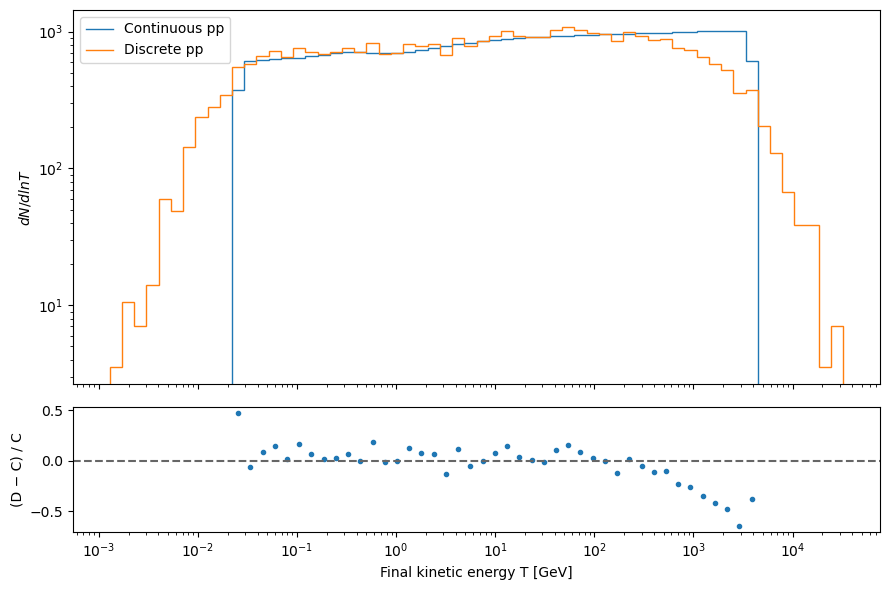

Particles included in common bins: 10000 10000


In [2]:
energy_bins = np.logspace(np.log10(min(T_c.min(), T_d.min()) * 0.99), np.log10(max(T_c.max(), T_d.max()) * 1.01), 61)
energy_centers = np.sqrt(energy_bins[:-1] * energy_bins[1:])
dlnT = np.diff(np.log(energy_bins))
counts_c = np.histogram(T_c, bins=energy_bins)[0]
counts_d = np.histogram(T_d, bins=energy_bins)[0]
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
axes[0].stairs(counts_c / dlnT, energy_bins, label='Continuous pp')
axes[0].stairs(counts_d / dlnT, energy_bins, label='Discrete pp')
axes[0].set_yscale('log')
axes[0].set_ylabel(r'$dN/dln T$')
axes[0].legend()
good = counts_c > 0
axes[1].plot(energy_centers[good], (counts_d[good] - counts_c[good]) / counts_c[good], 'o', ms=3)
axes[1].axhline(0, color='0.4', linestyle='--')
axes[1].set_xscale('log')
axes[1].set_xlabel('Final kinetic energy T [GeV]')
axes[1].set_ylabel('(D − C) / C')
fig.tight_layout()
plt.show()
print('Particles included in common bins:', counts_c.sum(), counts_d.sum())

## 2. 能谱与平均能量随时间演化

选择四个共同快照比较谱形；能谱分箱覆盖所有快照。均值、16%–84% 分位区间和平均动能比随时间显示。分位区间反映粒子群分布，不是均值误差棒；宽初始谱本身也贡献谱宽。

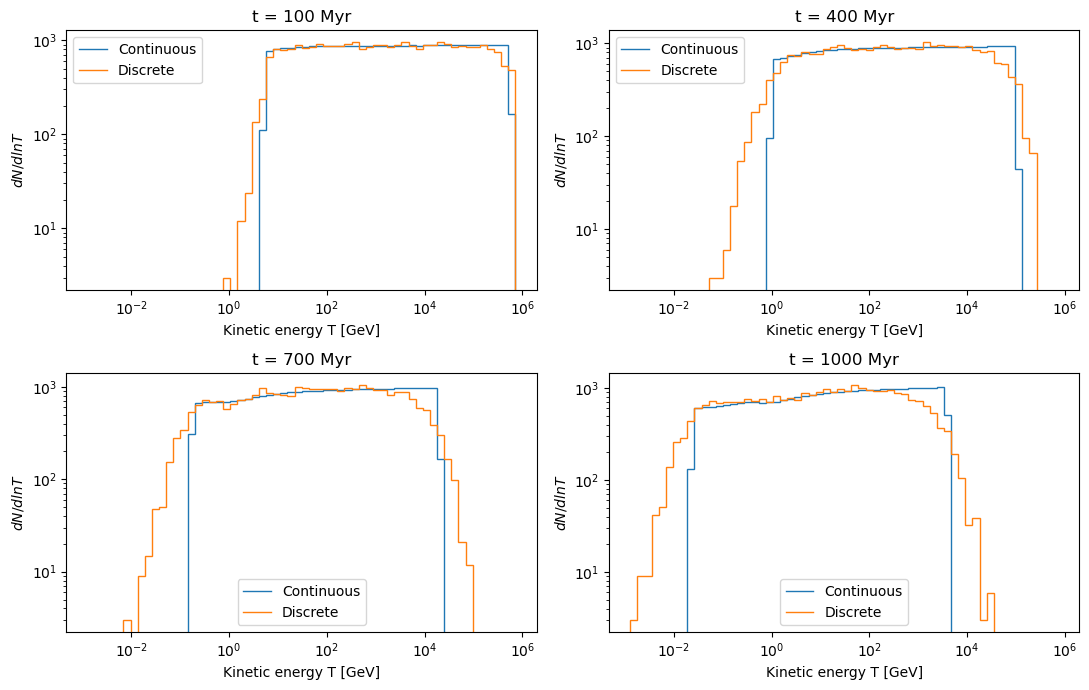

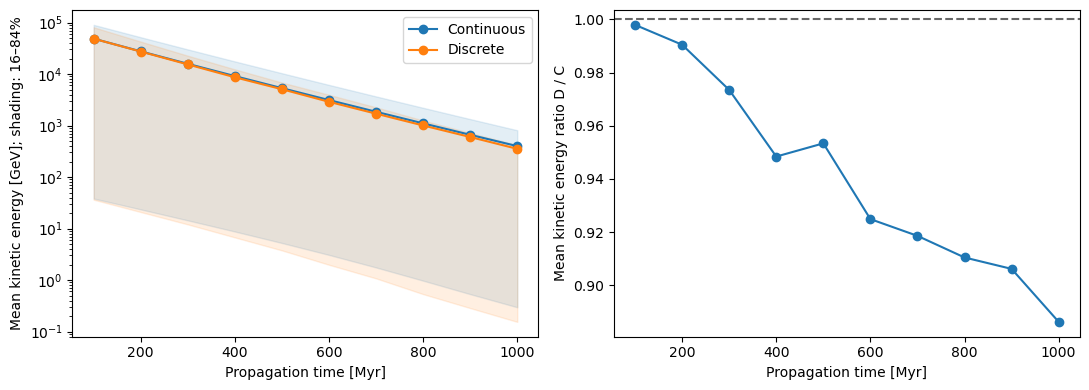

In [3]:
T_history_c = history_c[:, :, 6] - m_p
T_history_d = history_d[:, :, 6] - m_p
snapshot_bins = np.logspace(np.log10(min(T_history_c.min(), T_history_d.min()) * 0.99), np.log10(max(T_history_c.max(), T_history_d.max()) * 1.01), 61)
snapshot_width = np.diff(np.log(snapshot_bins))
selected_times = np.linspace(0, len(times) - 1, 4).astype(int)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, j in zip(axes.flat, selected_times):
    ax.stairs(np.histogram(T_history_c[:, j], bins=snapshot_bins)[0] / snapshot_width, snapshot_bins, label='Continuous')
    ax.stairs(np.histogram(T_history_d[:, j], bins=snapshot_bins)[0] / snapshot_width, snapshot_bins, label='Discrete')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Kinetic energy T [GeV]')
    ax.set_ylabel(r'$dN/dln T$')
    ax.set_title(f't = {times[j] / 1e6:.0f} Myr')
    ax.legend()
fig.tight_layout()
plt.show()

mean_c = T_history_c.mean(axis=0)
mean_d = T_history_d.mean(axis=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for T_history, label in [(T_history_c, 'Continuous'), (T_history_d, 'Discrete')]:
    low, high = np.percentile(T_history, [16, 84], axis=0)
    line = axes[0].plot(times / 1e6, T_history.mean(axis=0), 'o-', label=label)[0]
    axes[0].fill_between(times / 1e6, low, high, color=line.get_color(), alpha=0.12)
axes[0].set_yscale('log')
axes[0].set_ylabel('Mean kinetic energy [GeV]; shading: 16–84%')
axes[0].legend()
axes[1].plot(times / 1e6, mean_d / mean_c, 'o-')
axes[1].axhline(1, color='0.4', linestyle='--')
axes[1].set_ylabel('Mean kinetic energy ratio D / C')
for ax in axes:
    ax.set_xlabel('Propagation time [Myr]')
fig.tight_layout()
plt.show()

## 3. 按初始能量比较冷却和未碰撞比例

分立模型的“未碰撞”不等于“未冷却”：没有 pp 碰撞的粒子仍发生绝热冷却。其精确存活概率为
$$P_0(T_0,t)=expleft[-int_0^t n_H c,sigma_{pp}(T_{
m ad}(s)),ds
ight],$$
$$p_{
m ad}^2(s)=T_0(T_0+2m_p)e^{-2as/3},qquad T_{
m ad}=rac{p_{
m ad}^2}{sqrt{m_p^2+p_{
m ad}^2}+m_p}.$$
下面以无碰撞绝热轨迹积分碰撞率，检查零碰撞比例。`P0` 是分立模型的参考概率；连续冷却模型没有碰撞计数，不能将其 `-1` 当成零碰撞。

在每个初始能量 bin 内，误差尺度为 $sqrt{sum_i P_{0,i}(1-P_{0,i})}/N_{
m bin}$，对应独立粒子的 Bernoulli 波动。

Survival reference refinement, max absolute change: 1.5353317298072433e-08
Mean P0 (MC, reference): 0.0453 0.04509158018202121
Expected standard error: 0.0020481870884284594


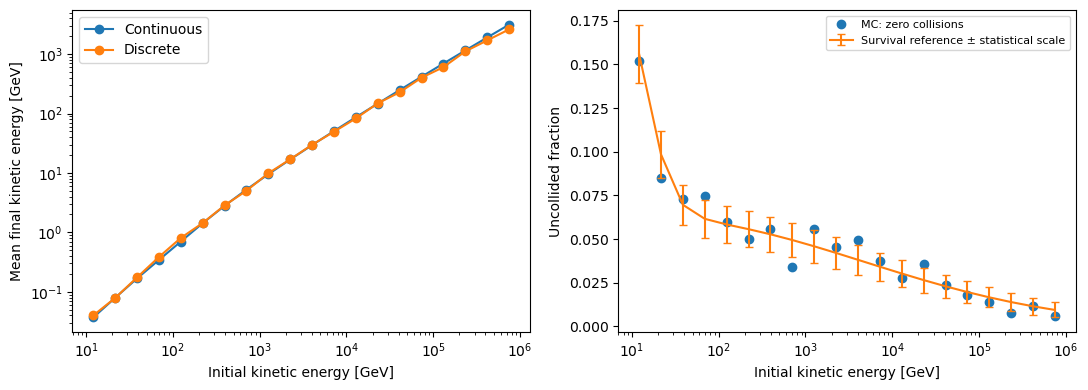

In [4]:
def sigma_pp(T):
    safe = np.maximum(T, 0.2797)
    L = np.log(safe / 0.2797)
    sigma = (30.7 - 0.96 * L + 0.18 * L**2) * (1 - (0.2797 / safe)**1.9)**3 * 1e-27
    return np.where(T > 0.2797, sigma, 0.0)


def survival_probability(N_time):
    # Trapezoidal integration of Gamma along each particle's adiabatic-only
    # trajectory; use a time loop to avoid a large particle-by-time array.
    integration_times = np.linspace(0, T_end, N_time)
    optical_depth = np.zeros(N)
    previous_rate = nH * c_cm_s * yr2s * sigma_pp(T0)
    for j in range(1, N_time):
        p2 = T0 * (T0 + 2 * m_p) * np.exp(-2 * a * integration_times[j] / 3)
        T_ad = p2 / (np.sqrt(m_p**2 + p2) + m_p)
        rate = nH * c_cm_s * yr2s * sigma_pp(T_ad)
        optical_depth += (previous_rate + rate) / 2 * (integration_times[j] - integration_times[j-1])
        previous_rate = rate
    return np.exp(-optical_depth)


P0 = survival_probability(2049)
P0_fine = survival_probability(4097)
print('Survival reference refinement, max absolute change:', np.max(np.abs(P0 - P0_fine)))
print('Mean P0 (MC, reference):', np.mean(N_collisions == 0), P0.mean())
print('Expected standard error:', np.sqrt(np.sum(P0 * (1 - P0))) / N)
initial_bins = np.logspace(np.log10(T0.min() * 0.999), np.log10(T0.max() * 1.001), 21)
initial_centers = np.sqrt(initial_bins[:-1] * initial_bins[1:])
conditional_c = np.zeros(20)
conditional_d = np.zeros(20)
zero_mc = np.zeros(20)
zero_reference = np.zeros(20)
zero_error = np.zeros(20)
for j in range(20):
    selected = (T0 >= initial_bins[j]) & (T0 < initial_bins[j+1])
    conditional_c[j] = T_c[selected].mean()
    conditional_d[j] = T_d[selected].mean()
    zero_mc[j] = np.mean(N_collisions[selected] == 0)
    zero_reference[j] = P0[selected].mean()
    zero_error[j] = np.sqrt(np.sum(P0[selected] * (1 - P0[selected]))) / selected.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(initial_centers, conditional_c, 'o-', label='Continuous')
axes[0].plot(initial_centers, conditional_d, 'o-', label='Discrete')
axes[0].set_yscale('log')
axes[0].set_ylabel('Mean final kinetic energy [GeV]')
axes[0].legend()
axes[1].plot(initial_centers, zero_mc, 'o', label='MC: zero collisions')
axes[1].errorbar(initial_centers, zero_reference, yerr=zero_error, fmt='-', capsize=3, label='Survival reference ± statistical scale')
axes[1].set_ylabel('Uncollided fraction')
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xscale('log')
    ax.set_xlabel('Initial kinetic energy [GeV]')
fig.tight_layout()
plt.show()

## 4. 扩散与对流的空间反馈

两种模型使用共同空间随机数，但能量变化不同会改变各自的扩散系数。因此位置不应被强制相同。比较最终柱半径 $R$、高度 $|z|$ 的累计粒子比例，以及随时间的横向均方根半径和高度。线性风无逃逸边界，会在长时间产生很大的高度；这是当前模型设置的结果。

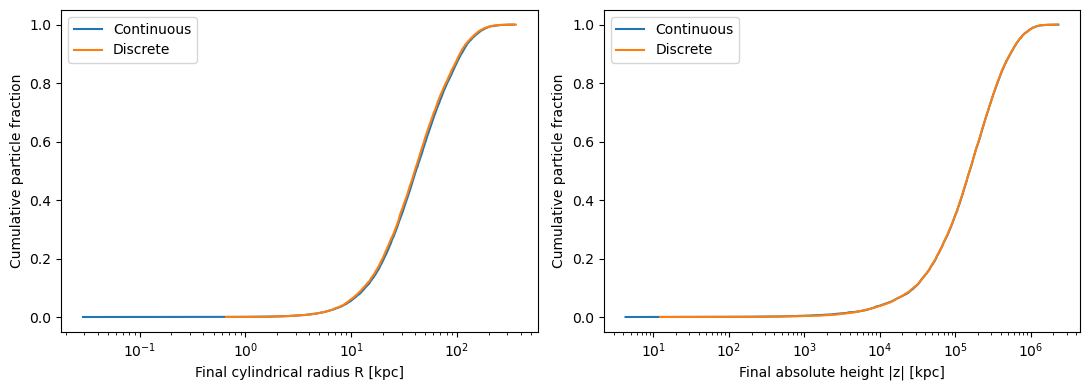

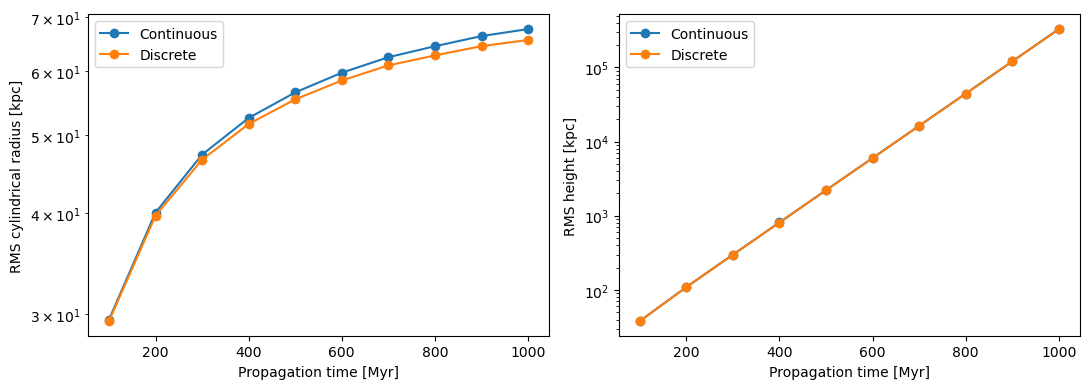

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for final, label in [(final_c, 'Continuous'), (final_d, 'Discrete')]:
    R = np.hypot(final[:, 3], final[:, 4]) / 1000
    Z = np.abs(final[:, 5]) / 1000
    for ax, coordinate in zip(axes, [R, Z]):
        ax.plot(np.sort(coordinate), np.arange(1, N + 1) / N, label=label)
for ax, label in zip(axes, ['Final cylindrical radius R [kpc]', 'Final absolute height |z| [kpc]']):
    ax.set_xscale('log')
    ax.set_xlabel(label)
    ax.set_ylabel('Cumulative particle fraction')
    ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for history, label in [(history_c, 'Continuous'), (history_d, 'Discrete')]:
    rms_R = np.sqrt(np.mean(history[:, :, 3]**2 + history[:, :, 4]**2, axis=0)) / 1000
    rms_z = np.sqrt(np.mean(history[:, :, 5]**2, axis=0)) / 1000
    axes[0].plot(times / 1e6, rms_R, 'o-', label=label)
    axes[1].plot(times / 1e6, rms_z, 'o-', label=label)
for ax, label in zip(axes, ['RMS cylindrical radius [kpc]', 'RMS height [kpc]']):
    ax.set_yscale('log')
    ax.set_xlabel('Propagation time [Myr]')
    ax.set_ylabel(label)
    ax.legend()
fig.tight_layout()
plt.show()

## 5. 观测环内的时间占据谱

观测区是半径 8 kpc、管半径 100 pc 的同一环管，不再随质子能量改变。记录中的 `dt` 是端点占据积分的时间权重。比较
$$rac{1}{t_{
m end}}rac{sum_{
m bin}dt}{Deltaln T},$$
即时间平均的环管内粒子数谱，而不是原始记录次数。它不是首次到达谱，也不是穿过表面的通量。若需数密度，再除以环管体积 $2pi^2R_oplus r_{
m tube}^2$。

同一粒子的重复占据具有相关性，下面同时报告实际访问过环管的独立粒子数，不给原始步记录套用 Poisson 误差。局部谱通常比全体谱更依赖粒子统计与时间步收敛。

Continuous : records = 87275 , visiting particles = 2972 , time-averaged ring particle count = 0.087275
Discrete : records = 86864 , visiting particles = 2965 , time-averaged ring particle count = 0.086864


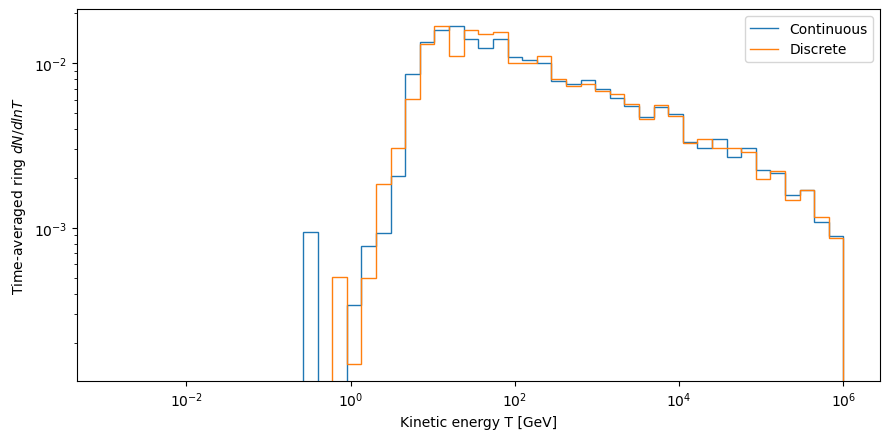

In [6]:
occupancy_energies = [T_c, T_d]
for records in [occupancy_c, occupancy_d]:
    if len(records) > 0:
        occupancy_energies.append(records[:, 1] - m_p)
local_min = min(values.min() for values in occupancy_energies)
local_max = max(values.max() for values in occupancy_energies)
local_bins = np.logspace(np.log10(local_min * 0.99), np.log10(local_max * 1.01), 51)
local_width = np.diff(np.log(local_bins))
fig, ax = plt.subplots(figsize=(9, 4.5))
for records, label in [(occupancy_c, 'Continuous'), (occupancy_d, 'Discrete')]:
    weighted_counts = np.histogram(records[:, 1] - m_p, bins=local_bins, weights=records[:, 3])[0]
    ax.stairs(weighted_counts / T_end / local_width, local_bins, label=label)
    print(label, ': records =', len(records), ', visiting particles =', len(np.unique(records[:, 0])),
          ', time-averaged ring particle count =', records[:, 3].sum() / T_end)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Kinetic energy T [GeV]')
ax.set_ylabel(r'Time-averaged ring $dN/dln T$')
ax.legend()
fig.tight_layout()
plt.show()

## 结果的适用范围

先看全体粒子谱和按初始能量分组的冷却差异，再看这些能量差异如何反馈到空间分布和观测环谱。共同随机数可以减小某些比较中的抽样波动，但不能消除统计误差。输入谱是确定性对数网格，不应使用独立随机注入样本的 KS p 值。

当前比较检验固定非弹性度 κ=0.5 的连续与分立 pp 能损模型。它不包含完整次级粒子产生、空间变化气体密度或逃逸。连续方程的精确求解也不会消除连续近似本身与有限能量跳跃过程的差别。采用更小 dt、独立随机种子或更多粒子重跑，可分别检查数值收敛与抽样误差。